# 🧠 인공지능 모델 구현
---


## 선형 회귀
- sklearn의 diabetes(당뇨병) 데이터 활용
- LinearRegression.py에 모델 구현
- 이 페이지에서 import해서 실행

### 📝데이터 분석

In [28]:
from sklearn.datasets import load_diabetes
from matplotlib import pyplot as plt
from pandas import DataFrame
import numpy as np

In [29]:
diabetes = load_diabetes()

In [30]:
print(diabetes.data.shape, diabetes.target.shape) # data는 10개의 특성을 가지는 442개 데이터

(442, 10) (442,)


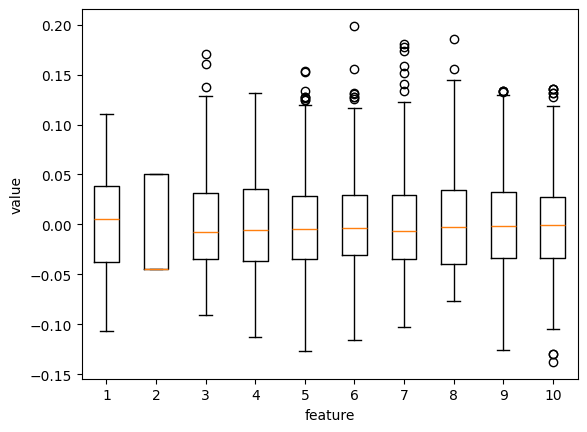

In [31]:
plt.boxplot(diabetes.data)
plt.xlabel("feature")
plt.ylabel("value")
plt.show()

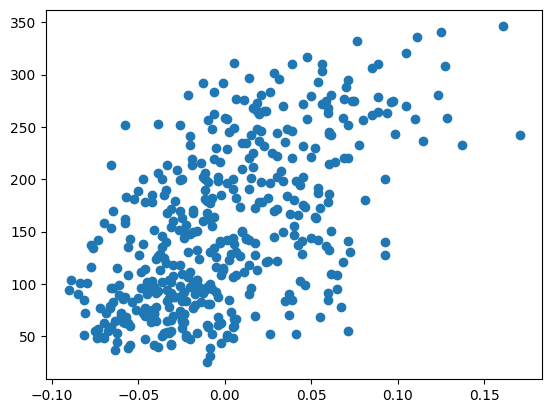

In [32]:
plt.scatter(diabetes.data[:, 2], diabetes.target)
plt.show()

In [33]:
x = diabetes.data[:, 2]
y = diabetes.target

1.0 1.0
913.5973364346786 123.39414383177173


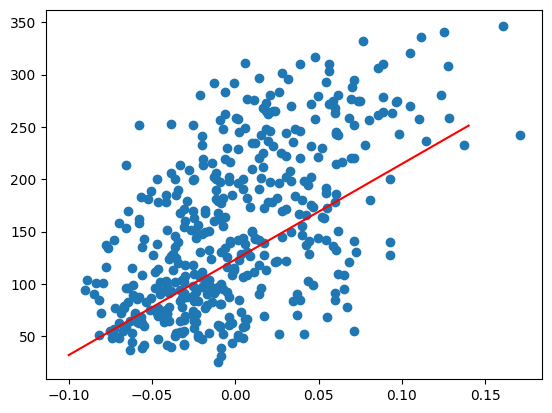

In [34]:
from LinearRegression import LinearRegression

LR = LinearRegression()
print(LR.w, LR.b)
LR.fit(x, y, 100)
print(LR.w, LR.b)

plt.scatter(x, y)
pt1 = (-0.1, -0.1 * LR.w + LR.b)
pt2 = (0.14, 0.14 * LR.w + LR.b)
plt.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], color="red")
plt.show()

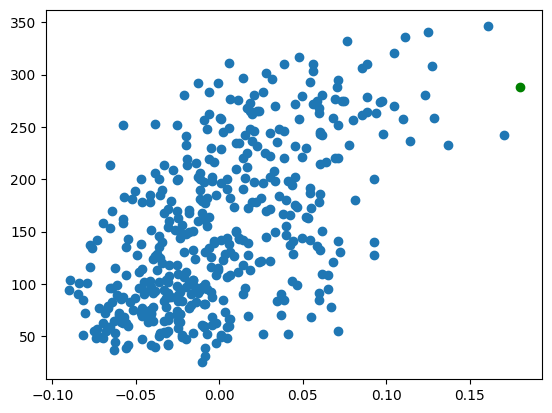

In [35]:
x_new = 0.18
y_pred = LR.predict(x_new)

plt.scatter(x, y)
plt.scatter(x_new, y_pred, color="green")
plt.show()

1. 전체 배치 (Full Batch Gradient Descent)
- 업데이트 횟수: 에포크당 딱 1번.

- 방식: 전체 데이터셋에 대한 오차(Error)를 모두 계산해서 평균을 낸 뒤, 그 값을 바탕으로 딱 한 번 가중치를 수정합니다.

- 특징: 학습이 매우 안정적이지만, 데이터가 너무 많으면 메모리가 부족하고 계산 시간이 너무 오래 걸립니다.

2. 미니 배치 (Mini-batch Gradient Descent)
- 업데이트 횟수: 에포크당 (전체 데이터 수 / 배치 사이즈)번.

- 방식: 데이터를 작은 덩어리(예: 32개, 64개씩)로 나누고, 각 덩어리를 볼 때마다 가중치를 수정합니다.

- 특징: 배치와 확률적 방식(SGD)의 장점을 섞은 것입니다. 메모리 효율이 좋고 학습 속도가 빨라 현대 딥러닝에서 가장 많이 쓰입니다.

3. 확률적 경사 하강법 (Stochastic Gradient Descent, SGD)
- 업데이트 횟수: 에포크당 데이터 개수(N)만큼.

- 방식: 데이터 한 개를 볼 때마다 즉시 가중치를 수정합니다. (질문자님이 앞서 보여주신 파이썬 코드 방식입니다.)

- 특징: 업데이트가 매우 빈번해서 학습 경로가 심하게 요동치지만, 국소 최적해(Local Minimum)를 탈출하는 데 유리할 때가 있습니다.

- SGD는 매 시행마다 서로 다른 손실 함수 지형 위를 걷는 것과 같다(매번 새로운 데이터에 대해서 손실을 계산하기 때문에 파라미터 - 손실 함수가 변함).

- 위의 이유로 요동침.

1. 이동 횟수 (Update Frequency)
질문하신 대로, 같은 데이터 한 바퀴(1 Epoch)를 돌아도 이동 횟수가 완전히 다릅니다.

- Full Batch: 데이터 1,000개를 다 공부하고 "아, 이 방향이구나!" 깨닫고 딱 한 걸음 이동합니다.

- SGD: 데이터 1,000개를 하나 볼 때마다 "오, 이쪽인가?", "아니, 저쪽인가?" 하며 1,000번 이동합니다.

2. 이동의 정확도와 경로 (Path)
- Full Batch (우직한 거인): 전체 데이터를 다 보고 평균적인 방향을 잡기 때문에, 가장 정확하고 매끄러운 직선 경로로 최솟값을 향해 내려갑니다.

- SGD (술 취한 보행자): 각 데이터(샘플)마다 목소리가 다르기 때문에, 어떤 데이터는 "오른쪽으로 가!" 하고 어떤 데이터는 "왼쪽으로 가!" 합니다. 그래서 지그재그로 요동치며(Fluctuation) 이동합니다.

### 배치 선형회귀

1.0 1.0
850.9598475167205 152.1334841628961


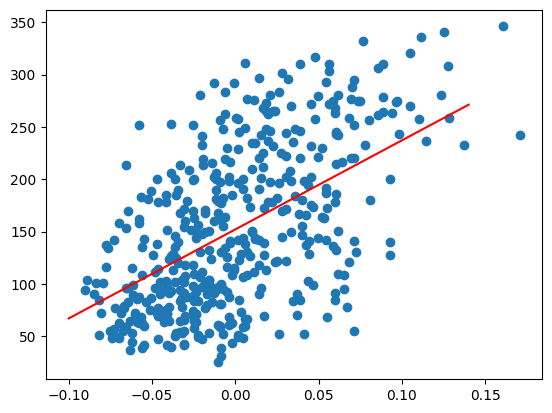

In [36]:
from LinearRegression import BatchLinearRegression

class BatchLinearRegression:  # full batch
    def __init__(self):
        self.w = 1.0
        self.b = 1.0

    def forpass(self, x):
        y_hat = x * self.w + self.b
        return y_hat

    def backprop(self, x, err):
        w_grad = x * err
        b_grad = err
        return w_grad, b_grad

    def fit(self, x, y, epochs=100, batch=10):
        for _ in range(epochs):
            y_hat = self.forpass(x)
            err = y_hat - y
            w_grad, b_grad = self.backprop(x, err)
            self.w -= np.mean(w_grad)
            self.b -= np.mean(b_grad)

    def predict(self, x):
        return self.forpass(x)

BLR = BatchLinearRegression()
print(BLR.w, BLR.b)
BLR.fit(x, y, 1000) # SGD와 비슷한 결과에 도달하기 위해서는 배치는 더 많은 Epoch이 필요함.
print(BLR.w, BLR.b)


plt.scatter(x, y)
pt1 = (-0.1, -0.1 * BLR.w + BLR.b)
pt2 = (0.14, 0.14 * BLR.w + BLR.b)
plt.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], color="red")
plt.show()

In [37]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

In [38]:
print(cancer.data.shape, cancer.target.shape)

(569, 30) (569,)


In [39]:
df = DataFrame(cancer.data[:3])
print(df)

      0      1      2       3        4        5       6        7       8   \
0  17.99  10.38  122.8  1001.0  0.11840  0.27760  0.3001  0.14710  0.2419   
1  20.57  17.77  132.9  1326.0  0.08474  0.07864  0.0869  0.07017  0.1812   
2  19.69  21.25  130.0  1203.0  0.10960  0.15990  0.1974  0.12790  0.2069   

        9   ...     20     21     22      23      24      25      26      27  \
0  0.07871  ...  25.38  17.33  184.6  2019.0  0.1622  0.6656  0.7119  0.2654   
1  0.05667  ...  24.99  23.41  158.8  1956.0  0.1238  0.1866  0.2416  0.1860   
2  0.05999  ...  23.57  25.53  152.5  1709.0  0.1444  0.4245  0.4504  0.2430   

       28       29  
0  0.4601  0.11890  
1  0.2750  0.08902  
2  0.3613  0.08758  

[3 rows x 30 columns]


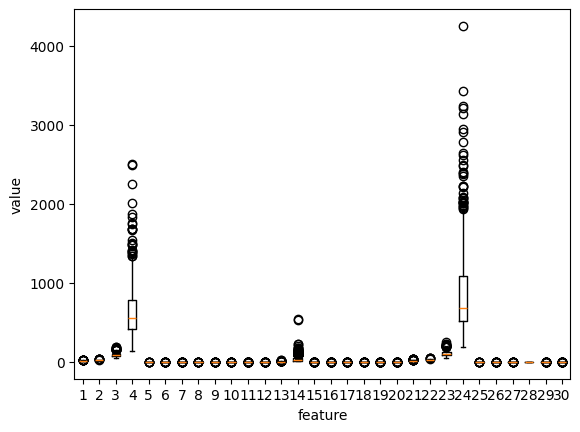

In [40]:
plt.boxplot(cancer.data)
plt.xlabel("feature")
plt.ylabel("value")
plt.show()

In [41]:
print(np.unique(cancer.target, return_counts=True))

(array([0, 1]), array([212, 357]))


In [42]:
from sklearn.model_selection import train_test_split

x = cancer.data
y = cancer.target

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42) 

In [43]:
print(np.unique(y_train, return_counts=True))
print(np.unique(y_test, return_counts=True))

(array([0, 1]), array([169, 286]))
(array([0, 1]), array([43, 71]))


In [44]:
class LogisticRegression:  # stochastic
    def __init__(self):
        self.w = None
        self.b = None

    def forpass(self, x):
        y_hat = np.dot(x, self.w) + self.b
        return y_hat

    def backprop(self, x, err):
        w_grad = x * err
        b_grad = 1 * err
        return w_grad, b_grad

    def activation(self, z):
        z = np.clip(z, -100, None)
        return 1 / (1 + np.exp(-z))

    def fit(self, x, y, epochs=100):
        self.w = np.ones(x.shape[1])
        self.b = 0
        for _ in range(epochs):
            for x_i, y_i in zip(x, y):
                z = self.forpass(x_i)
                y_hat = self.activation(z)
                err = y_hat - y_i
                w_grad, b_grad = self.backprop(x_i, err)
                self.w -= w_grad
                self.b -= b_grad

    def predict(self, x):
        z = [self.forpass(x_i) for x_i in x]
        a = self.activation(z)
        return a > 0.5


neuron = LogisticRegression()
neuron.fit(x_train, y_train, 1000)
print(np.mean(neuron.predict(x_test) == y_test))

0.956140350877193


In [45]:
class BatchLogisticRegression:  # Batch
    def __init__(self, learning_rate= 0.1):
        self.w = None
        self.b = None
        self.lr = learning_rate

    def forpass(self, x):
        y_hat = np.dot(x, self.w) + self.b
        return y_hat

    def backprop(self, x, err):
        w_grad = np.dot(np.transpose(x), err)
        b_grad = np.sum(err)
        return w_grad, b_grad

    def activation(self, z):
        z = np.clip(z, -100, None)
        return 1 / (1 + np.exp(-z))

    def fit(self, x, y, epochs=1000):
        self.w = np.ones(x.shape[1])
        self.b = 0
        for _ in range(epochs):
            z = self.forpass(x)
            y_hat = self.activation(z)
            err = y_hat - y
            w_grad, b_grad = self.backprop(x, err)
            self.w -= self.lr * w_grad / x.shape[0]
            self.b -= self.lr * b_grad / x.shape[0]

    def predict(self, x):
        z = [self.forpass(x_i) for x_i in x]
        a = self.activation(z)
        return a > 0.5
    
bneuron = BatchLogisticRegression()
bneuron.fit(x_train, y_train, 10000)
print(np.mean(bneuron.predict(x_test) == y_test))

0.9473684210526315
